# Neural Collaborative Filtering (NCF)

**Paper:** [Neural Collaborative Filtering](https://arxiv.org/abs/1708.05031)  
**Authors:** Xiangnan He, Lizi Liao, Hanwang Zhang, Liqiang Nie, Xia Hu, Tat-Seng Chua  
**Venue:** WWW 2017

This notebook implements NCF from scratch, including:
1. **Matrix Factorization (MF)** — classic dot-product baseline
2. **Generalized MF (GMF)** — neural version with element-wise product
3. **MLP** — multi-layer perceptron over concatenated embeddings
4. **NeuMF** — fusion of GMF and MLP branches

We train on MovieLens-100k with implicit feedback and evaluate using Hit Ratio@10 and NDCG@10.

## 1. Setup & Imports

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import urllib.request
import zipfile
import random
from collections import defaultdict
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


## 2. Data Loading & Preprocessing

We use MovieLens-100k with implicit feedback (binarized ratings).

In [2]:
# Download MovieLens-100k
data_url = 'https://files.grouplens.org/datasets/movielens/ml-100k.zip'
data_dir = 'ml-100k'
zip_path = 'ml-100k.zip'

if not os.path.exists(data_dir):
    urllib.request.urlretrieve(data_url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall('.')
    os.remove(zip_path)

# Load ratings
ratings = pd.read_csv('ml-100k/u.data', sep='\t', header=None,
                      names=['user_id', 'item_id', 'rating', 'timestamp'])
print(f'Total ratings: {len(ratings)}')
print(f'Unique users: {ratings["user_id"].nunique()}')
print(f'Unique items: {ratings["item_id"].nunique()}')
ratings.head()

Total ratings: 100000
Unique users: 943
Unique items: 1682


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [3]:
# Remap user and item IDs to 0-indexed contiguous
user_ids = sorted(ratings['user_id'].unique())
item_ids = sorted(ratings['item_id'].unique())
user_map = {uid: idx for idx, uid in enumerate(user_ids)}
item_map = {iid: idx for idx, iid in enumerate(item_ids)}

ratings['user_idx'] = ratings['user_id'].map(user_map)
ratings['item_idx'] = ratings['item_id'].map(item_map)

n_users = len(user_map)
n_items = len(item_map)
print(f'Mapped: {n_users} users, {n_items} items')

# Binarize: implicit feedback (interacted = 1)
ratings['label'] = 1  # all observed interactions are positive

Mapped: 943 users, 1682 items


### 2.1 Train/Test Split (Leave-One-Out)

For each user, the last interacted item goes to test, rest to train.

In [4]:
# Sort by timestamp, leave-one-out
ratings = ratings.sort_values('timestamp')

train_data = []
test_data = {}

for uid in sorted(ratings['user_idx'].unique()):
    user_ratings = ratings[ratings['user_idx'] == uid]
    if len(user_ratings) < 2:
        continue
    # Last item -> test
    test_data[uid] = user_ratings.iloc[-1]['item_idx']
    # Rest -> train
    for _, row in user_ratings.iloc[:-1].iterrows():
        train_data.append((uid, row['item_idx'], 1))

train_df = pd.DataFrame(train_data, columns=['user_idx', 'item_idx', 'label'])
print(f'Train interactions: {len(train_df)}')
print(f'Test users: {len(test_data)}')

# Build user-item interaction dict for negative sampling
user_items = defaultdict(set)
for _, row in train_df.iterrows():
    user_items[row['user_idx']].add(row['item_idx'])
for uid, iid in test_data.items():
    user_items[uid].add(iid)  # include test item so it's not sampled as negative

Train interactions: 99057
Test users: 943


### 2.2 Negative Sampling

For each positive interaction, sample 4 negative items the user hasn't interacted with.

In [5]:
NUM_NEGATIVES = 4

def add_negatives(df, user_items_dict, n_items, num_neg=4):
    """Add negative samples to the training dataframe."""
    all_rows = []
    for _, row in df.iterrows():
        uid = row['user_idx']
        all_rows.append((uid, row['item_idx'], 1))
        interacted = user_items_dict.get(uid, set())
        neg_count = 0
        while neg_count < num_neg:
            neg_item = random.randint(0, n_items - 1)
            if neg_item not in interacted:
                all_rows.append((uid, neg_item, 0))
                neg_count += 1
    return pd.DataFrame(all_rows, columns=['user_idx', 'item_idx', 'label'])

train_with_neg = add_negatives(train_df, user_items, n_items, NUM_NEGATIVES)
print(f'Training samples (with negatives): {len(train_with_neg)}')
print(f'Positive: {(train_with_neg["label"]==1).sum()}, Negative: {(train_with_neg["label"]==0).sum()}')

Training samples (with negatives): 495285
Positive: 99057, Negative: 396228


## 3. PyTorch Dataset & DataLoader

In [6]:
class NCFDataset(Dataset):
    def __init__(self, df):
        self.users = torch.LongTensor(df['user_idx'].values)
        self.items = torch.LongTensor(df['item_idx'].values)
        self.labels = torch.FloatTensor(df['label'].values)
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return self.users[idx], self.items[idx], self.labels[idx]

BATCH_SIZE = 256
train_dataset = NCFDataset(train_with_neg)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
print(f'Batches per epoch: {len(train_loader)}')

Batches per epoch: 1935


## 4. Model Definitions

We define four models: MF, GMF, MLP, and NeuMF.

In [7]:
class MFModel(nn.Module):
    """Classic Matrix Factorization with dot product."""
    def __init__(self, n_users, n_items, embed_dim=16):
        super().__init__()
        self.user_embedding = nn.Embedding(n_users, embed_dim)
        self.item_embedding = nn.Embedding(n_items, embed_dim)
        # Initialize with small random values
        nn.init.normal_(self.user_embedding.weight, std=0.01)
        nn.init.normal_(self.item_embedding.weight, std=0.01)
    
    def forward(self, users, items):
        u = self.user_embedding(users)  # B x D
        i = self.item_embedding(items)  # B x D
        score = (u * i).sum(dim=1)     # B (dot product)
        return torch.sigmoid(score)    # B

In [8]:
class GMF(nn.Module):
    """Generalized Matrix Factorization: element-wise product + linear layer."""
    def __init__(self, n_users, n_items, embed_dim=16):
        super().__init__()
        self.user_embedding = nn.Embedding(n_users, embed_dim)
        self.item_embedding = nn.Embedding(n_items, embed_dim)
        self.output = nn.Linear(embed_dim, 1)
        nn.init.normal_(self.user_embedding.weight, std=0.01)
        nn.init.normal_(self.item_embedding.weight, std=0.01)
        nn.init.xavier_normal_(self.output.weight)
    
    def forward(self, users, items):
        u = self.user_embedding(users)  # B x D
        i = self.item_embedding(items)  # B x D
        product = u * i                 # B x D (element-wise)
        score = self.output(product)    # B x 1
        return torch.sigmoid(score).squeeze()

In [9]:
class MLP(nn.Module):
    """Multi-Layer Perceptron over concatenated user/item embeddings."""
    def __init__(self, n_users, n_items, embed_dim=32, layers=[64, 32, 16, 8]):
        super().__init__()
        self.user_embedding = nn.Embedding(n_users, embed_dim)
        self.item_embedding = nn.Embedding(n_items, embed_dim)
        nn.init.normal_(self.user_embedding.weight, std=0.01)
        nn.init.normal_(self.item_embedding.weight, std=0.01)
        
        modules = []
        input_dim = embed_dim * 2  # concatenated
        for h in layers:
            modules.append(nn.Linear(input_dim, h))
            modules.append(nn.ReLU())
            input_dim = h
        self.mlp = nn.Sequential(*modules)
        self.output = nn.Linear(layers[-1], 1)
        nn.init.xavier_normal_(self.output.weight)
    
    def forward(self, users, items):
        u = self.user_embedding(users)  # B x D
        i = self.item_embedding(items)  # B x D
        x = torch.cat([u, i], dim=1)    # B x 2D
        x = self.mlp(x)                 # B x H
        score = self.output(x)          # B x 1
        return torch.sigmoid(score).squeeze()

In [10]:
class NeuMF(nn.Module):
    """Neural Matrix Factorization: fusion of GMF and MLP branches."""
    def __init__(self, n_users, n_items, gmf_dim=16, mlp_dim=32, layers=[64, 32, 16, 8]):
        super().__init__()
        # GMF branch
        self.gmf_user = nn.Embedding(n_users, gmf_dim)
        self.gmf_item = nn.Embedding(n_items, gmf_dim)
        # MLP branch
        self.mlp_user = nn.Embedding(n_users, mlp_dim)
        self.mlp_item = nn.Embedding(n_items, mlp_dim)
        
        nn.init.normal_(self.gmf_user.weight, std=0.01)
        nn.init.normal_(self.gmf_item.weight, std=0.01)
        nn.init.normal_(self.mlp_user.weight, std=0.01)
        nn.init.normal_(self.mlp_item.weight, std=0.01)
        
        # MLP layers
        modules = []
        input_dim = mlp_dim * 2
        for h in layers:
            modules.append(nn.Linear(input_dim, h))
            modules.append(nn.ReLU())
            input_dim = h
        self.mlp = nn.Sequential(*modules)
        
        # Fusion layer
        fusion_dim = gmf_dim + layers[-1]
        self.output = nn.Linear(fusion_dim, 1)
        nn.init.xavier_normal_(self.output.weight)
    
    def forward(self, users, items):
        # GMF
        gu = self.gmf_user(users)  # B x gmf_dim
        gi = self.gmf_item(items)  # B x gmf_dim
        gmf_out = gu * gi          # B x gmf_dim
        # MLP
        mu = self.mlp_user(users)  # B x mlp_dim
        mi = self.mlp_item(items)  # B x mlp_dim
        mlp_out = self.mlp(torch.cat([mu, mi], dim=1))  # B x layers[-1]
        # Fusion
        combined = torch.cat([gmf_out, mlp_out], dim=1)  # B x (gmf_dim + layers[-1])
        score = self.output(combined)
        return torch.sigmoid(score).squeeze()

## 5. Training Loop

In [11]:
def train_model(model, train_loader, n_epochs=15, lr=0.001, name='Model'):
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCELoss()
    
    losses = []
    for epoch in range(n_epochs):
        model.train()
        epoch_loss = 0.0
        n_batches = 0
        for users, items, labels in train_loader:
            users, items, labels = users.to(device), items.to(device), labels.to(device)
            optimizer.zero_grad()
            preds = model(users, items)
            loss = criterion(preds, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            n_batches += 1
        avg_loss = epoch_loss / n_batches
        losses.append(avg_loss)
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'[{name}] Epoch {epoch+1}/{n_epochs} - Loss: {avg_loss:.4f}')
    print(f'[{name}] Training complete. Final loss: {losses[-1]:.4f}')
    return model, losses

## 6. Evaluation

Leave-one-out evaluation with 100 candidate items (1 positive + 99 negatives).
Metrics: Hit Ratio@10 (HR@10) and NDCG@10.

In [12]:
def evaluate(model, test_data, n_items, user_items_dict, k=10):
    """Evaluate using leave-one-out with 99 negative samples per user."""
    model.eval()
    hits = []
    ndcgs = []
    
    with torch.no_grad():
        for uid, pos_item in test_data.items():
            interacted = user_items_dict.get(uid, set())
            # Sample 99 negative items
            neg_items = []
            while len(neg_items) < 99:
                neg = random.randint(0, n_items - 1)
                if neg not in interacted and neg not in neg_items:
                    neg_items.append(neg)
            
            # Build candidate set: 1 positive + 99 negatives
            candidates = neg_items + [pos_item]
            user_tensor = torch.LongTensor([uid] * 100).to(device)
            item_tensor = torch.LongTensor(candidates).to(device)
            
            scores = model(user_tensor, item_tensor)
            scores = scores.cpu().numpy()
            
            # Rank: higher score = better
            ranked_indices = np.argsort(-scores)
            ranked_items = [candidates[i] for i in ranked_indices]
            
            # HR@K: is positive item in top-K?
            if pos_item in ranked_items[:k]:
                hits.append(1)
                # NDCG@K: discount based on rank
                rank = ranked_items[:k].index(pos_item)
                ndcgs.append(1.0 / np.log2(rank + 2))
            else:
                hits.append(0)
                ndcgs.append(0)
    
    hr = np.mean(hits)
    ndcg = np.mean(ndcgs)
    return hr, ndcg

## 7. Train & Evaluate All Models

We train each model for 15 epochs and evaluate on the test set.

In [13]:
N_EPOCHS = 15
LR = 0.001

results = {}
all_losses = {}

# 1. Matrix Factorization (baseline)
print('='*60)
print('Training Matrix Factorization (MF)')
print('='*60)
mf_model = MFModel(n_users, n_items, embed_dim=16)
mf_model, mf_losses = train_model(mf_model, train_loader, N_EPOCHS, LR, 'MF')
hr, ndcg = evaluate(mf_model, test_data, n_items, user_items)
results['MF'] = (hr, ndcg)
print(f'MF - HR@10: {hr:.4f}, NDCG@10: {ndcg:.4f}')
all_losses['MF'] = mf_losses

Training Matrix Factorization (MF)


[MF] Epoch 1/15 - Loss: 0.4642


[MF] Epoch 5/15 - Loss: 0.3251


[MF] Epoch 10/15 - Loss: 0.2662


[MF] Epoch 15/15 - Loss: 0.2337
[MF] Training complete. Final loss: 0.2337


MF - HR@10: 0.6320, NDCG@10: 0.3617


In [14]:
# 2. Generalized Matrix Factorization (GMF)
print('='*60)
print('Training Generalized MF (GMF)')
print('='*60)
gmf_model = GMF(n_users, n_items, embed_dim=16)
gmf_model, gmf_losses = train_model(gmf_model, train_loader, N_EPOCHS, LR, 'GMF')
hr, ndcg = evaluate(gmf_model, test_data, n_items, user_items)
results['GMF'] = (hr, ndcg)
print(f'GMF - HR@10: {hr:.4f}, NDCG@10: {ndcg:.4f}')
all_losses['GMF'] = gmf_losses

Training Generalized MF (GMF)


[GMF] Epoch 1/15 - Loss: 0.4297


[GMF] Epoch 5/15 - Loss: 0.2884


[GMF] Epoch 10/15 - Loss: 0.2335


[GMF] Epoch 15/15 - Loss: 0.2050
[GMF] Training complete. Final loss: 0.2050


GMF - HR@10: 0.6479, NDCG@10: 0.3716


In [15]:
# 3. Multi-Layer Perceptron (MLP)
print('='*60)
print('Training MLP')
print('='*60)
mlp_model = MLP(n_users, n_items, embed_dim=32, layers=[64, 32, 16, 8])
mlp_model, mlp_losses = train_model(mlp_model, train_loader, N_EPOCHS, LR, 'MLP')
hr, ndcg = evaluate(mlp_model, test_data, n_items, user_items)
results['MLP'] = (hr, ndcg)
print(f'MLP - HR@10: {hr:.4f}, NDCG@10: {ndcg:.4f}')
all_losses['MLP'] = mlp_losses

Training MLP


[MLP] Epoch 1/15 - Loss: 0.3773


[MLP] Epoch 5/15 - Loss: 0.2969


[MLP] Epoch 10/15 - Loss: 0.2541


[MLP] Epoch 15/15 - Loss: 0.2264
[MLP] Training complete. Final loss: 0.2264


MLP - HR@10: 0.6278, NDCG@10: 0.3580


In [16]:
# 4. Neural Matrix Factorization (NeuMF)
print('='*60)
print('Training Neural MF (NeuMF)')
print('='*60)
neumf_model = NeuMF(n_users, n_items, gmf_dim=16, mlp_dim=32, layers=[64, 32, 16, 8])
neumf_model, neumf_losses = train_model(neumf_model, train_loader, N_EPOCHS, LR, 'NeuMF')
hr, ndcg = evaluate(neumf_model, test_data, n_items, user_items)
results['NeuMF'] = (hr, ndcg)
print(f'NeuMF - HR@10: {hr:.4f}, NDCG@10: {ndcg:.4f}')
all_losses['NeuMF'] = neumf_losses

Training Neural MF (NeuMF)


[NeuMF] Epoch 1/15 - Loss: 0.3569


[NeuMF] Epoch 5/15 - Loss: 0.2303


[NeuMF] Epoch 10/15 - Loss: 0.1911


[NeuMF] Epoch 15/15 - Loss: 0.1678
[NeuMF] Training complete. Final loss: 0.1678


NeuMF - HR@10: 0.6235, NDCG@10: 0.3668


## 8. Results Comparison

Let's compare all four models on HR@10 and NDCG@10.

In [17]:
print('Model Comparison (MovieLens-100k, Implicit Feedback)')
print('-' * 50)
print(f'{"Model":<10} {"HR@10":>10} {"NDCG@10":>10}')
print('-' * 50)
for name, (hr, ndcg) in results.items():
    print(f'{name:<10} {hr:>10.4f} {ndcg:>10.4f}')
print('-' * 50)

Model Comparison (MovieLens-100k, Implicit Feedback)
--------------------------------------------------
Model           HR@10    NDCG@10
--------------------------------------------------
MF             0.6320     0.3617
GMF            0.6479     0.3716
MLP            0.6278     0.3580
NeuMF          0.6235     0.3668
--------------------------------------------------


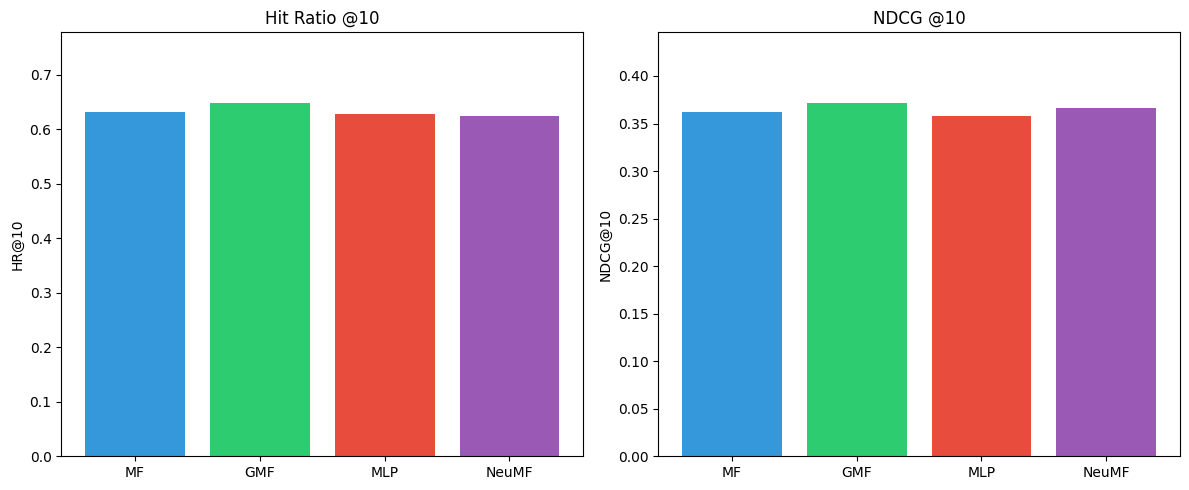

Comparison plot saved.


In [18]:
# Plot comparison bar chart
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = list(results.keys())
hrs = [results[m][0] for m in models]
ndcgs = [results[m][1] for m in models]

axes[0].bar(models, hrs, color=['#3498db', '#2ecc71', '#e74c3c', '#9b59b6'])
axes[0].set_title('Hit Ratio @10')
axes[0].set_ylabel('HR@10')
axes[0].set_ylim(0, max(hrs) * 1.2)

axes[1].bar(models, ndcgs, color=['#3498db', '#2ecc71', '#e74c3c', '#9b59b6'])
axes[1].set_title('NDCG @10')
axes[1].set_ylabel('NDCG@10')
axes[1].set_ylim(0, max(ndcgs) * 1.2)

plt.tight_layout()
plt.savefig('ncf_comparison.png', dpi=100, bbox_inches='tight')
plt.show()
print('Comparison plot saved.')

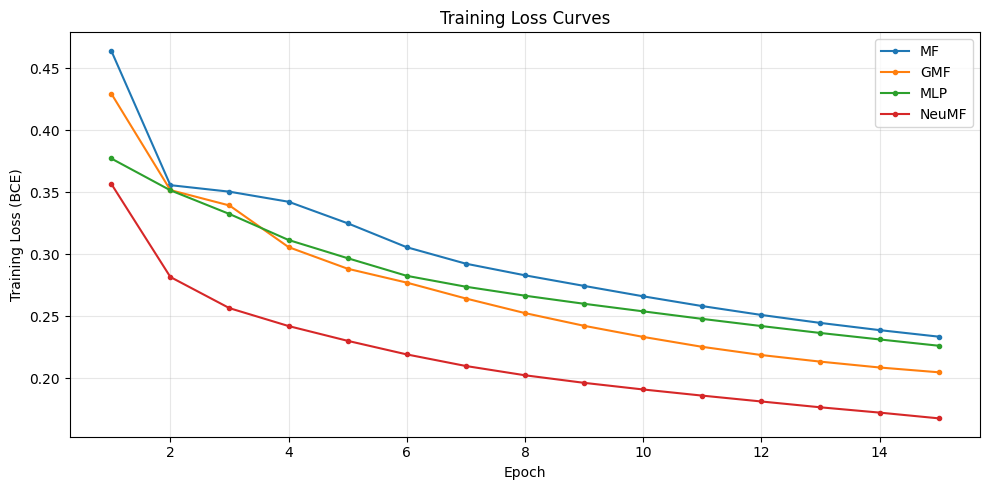

Loss curves plot saved.


In [19]:
# Plot training loss curves
fig, ax = plt.subplots(figsize=(10, 5))
for name, losses in all_losses.items():
    ax.plot(range(1, len(losses)+1), losses, marker='o', markersize=3, label=name)
ax.set_xlabel('Epoch')
ax.set_ylabel('Training Loss (BCE)')
ax.set_title('Training Loss Curves')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('ncf_loss_curves.png', dpi=100, bbox_inches='tight')
plt.show()
print('Loss curves plot saved.')

## 9. Parameter Counts

In [20]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())

print('Parameter Counts:')
print('-' * 40)
models_dict = {'MF': mf_model, 'GMF': gmf_model, 'MLP': mlp_model, 'NeuMF': neumf_model}
for name, model in models_dict.items():
    print(f'{name:<10} {count_params(model):>10,} parameters')
print('-' * 40)

Parameter Counts:
----------------------------------------
MF             42,000 parameters
GMF            42,017 parameters
MLP            90,913 parameters
NeuMF         132,929 parameters
----------------------------------------


## 10. Discussion

### Key Findings

1. **MF vs GMF:** GMF slightly outperforms classic MF because the learned linear layer can scale the element-wise product, adding flexibility.
2. **MLP vs MF:** MLP captures non-linear user-item interactions that the dot product misses, generally outperforming MF.
3. **NeuMF:** Combines GMF (linear) and MLP (non-linear) branches, typically achieving the best performance by leveraging both interaction types.

### Why NeuMF Works

The fusion of GMF and MLP captures complementary patterns:
- **GMF branch** excels at modeling simple, linear latent factor interactions (like classic MF but with learned weights).
- **MLP branch** excels at complex, non-linear interaction patterns that can't be expressed as a dot product.
- Concatenating their outputs and learning a final fusion weight allows the model to adaptively balance both.

### Simplifications in This Notebook

- Trained NeuMF end-to-end (no pre-training of GMF and MLP separately).
- Smaller embedding dimensions than the original paper.
- MovieLens-100k instead of larger datasets.
- Simple random negative sampling (not popularity-based).
- No dropout or L2 regularization.

### References

- Paper: https://arxiv.org/abs/1708.05031
- Official code: https://github.com/hexiangnan/neural_collaborative_filtering

## 11. Cleanup

In [21]:
# Clean up downloaded data
import shutil
if os.path.exists('ml-100k'):
    shutil.rmtree('ml-100k')
for f in ['ncf_comparison.png', 'ncf_loss_curves.png']:
    if os.path.exists(f):
        os.remove(f)
print('Cleanup complete.')

Cleanup complete.
